# Relationship between Commodities, Energy prices and Indexes
Analysing their correlations to each other and the UK energy prices. 

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yfinance as yf

# 1. Define your multi-asset tickers dictionary
tickers = {
    "Brent Crude": "BZ=F",
    "Natural Gas": "NG=F",
    "Gold": "GC=F",
    "S&P 500": "^GSPC",
    "UK FTSE 100": "^FTSE",
}

# 2. Download historical 'Close' prices for all tickers in one go
data = yf.download(list(tickers.values()), start="2016-10-01", end="2026-10-13")[
    "Close"
]

# Rename columns to friendly names
data = data.rename(columns={v: k for k, v in tickers.items()})

# 3. Calculate Daily Log Returns for all assets
log_returns = np.log(data / data.shift(1)).dropna()

# 4. Generate the Cross-Asset Correlation Matrix
correlation_matrix = log_returns.corr()

print("--- Cross-Asset Correlation Matrix ---")
print(correlation_matrix.round(3))

# 5. Calculate Annualized Volatility (Standard Deviation * sqrt(252)) for each asset
annualized_volatility = log_returns.std() * np.sqrt(252)

print("\n--- Annualized Volatility (Risk) ---")
print(annualized_volatility.round(4))

/opt/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
/opt/anaconda3/lib/python3.12/site-packages/pandas/core/arrays/masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (
/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_66438/3732555596.py:16: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download(list(tickers.values()), start="2016-10-01", end="2026-10-13")[
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()
[*********************100%***********************]  

--- Cross-Asset Correlation Matrix ---
Ticker       Brent Crude   Gold  Natural Gas  UK FTSE 100  S&P 500
Ticker                                                            
Brent Crude        1.000  0.047        0.078        0.209    0.197
Gold               0.047  1.000        0.015        0.077    0.093
Natural Gas        0.078  0.015        1.000        0.032    0.075
UK FTSE 100        0.209  0.077        0.032        1.000    0.498
S&P 500            0.197  0.093        0.075        0.498    1.000

--- Annualized Volatility (Risk) ---
Ticker
Brent Crude    0.4056
Gold           0.1699
Natural Gas    0.6899
UK FTSE 100    0.1487
S&P 500        0.1824
dtype: float64


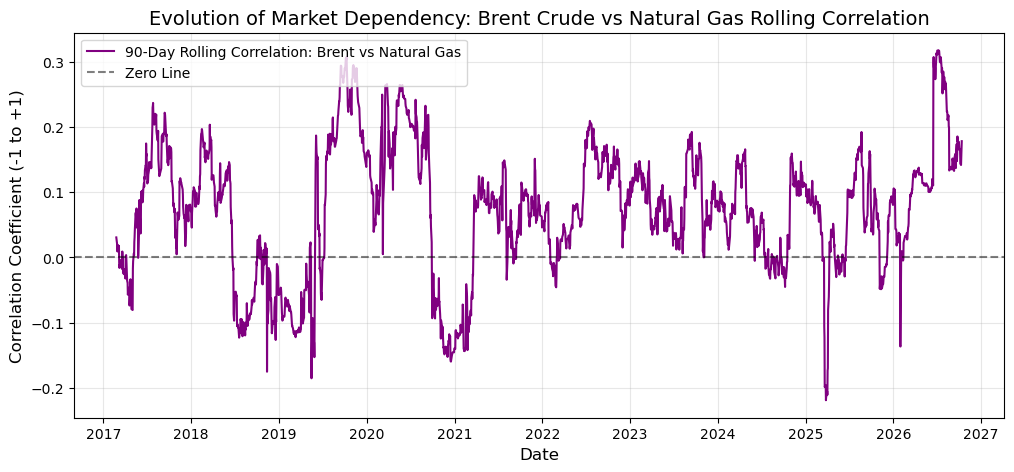

In [4]:
window_size = 90
rolling_corr = (
    log_returns["Brent Crude"]
    .rolling(window=window_size)
    .corr(log_returns["Natural Gas"])
)

# 5. Plot the rolling correlation over time
plt.figure(figsize=(12, 5))
plt.plot(
    rolling_corr.index,
    rolling_corr,
    label=f"{window_size}-Day Rolling Correlation: Brent vs Natural Gas",
    color="purple",
    linewidth=1.5,
)
plt.axhline(0, color="black", linestyle="--", alpha=0.5, label="Zero Line")
plt.title(
    "Evolution of Market Dependency: Brent Crude vs Natural Gas Rolling"
    " Correlation",
    fontsize=14,
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Correlation Coefficient (-1 to +1)", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

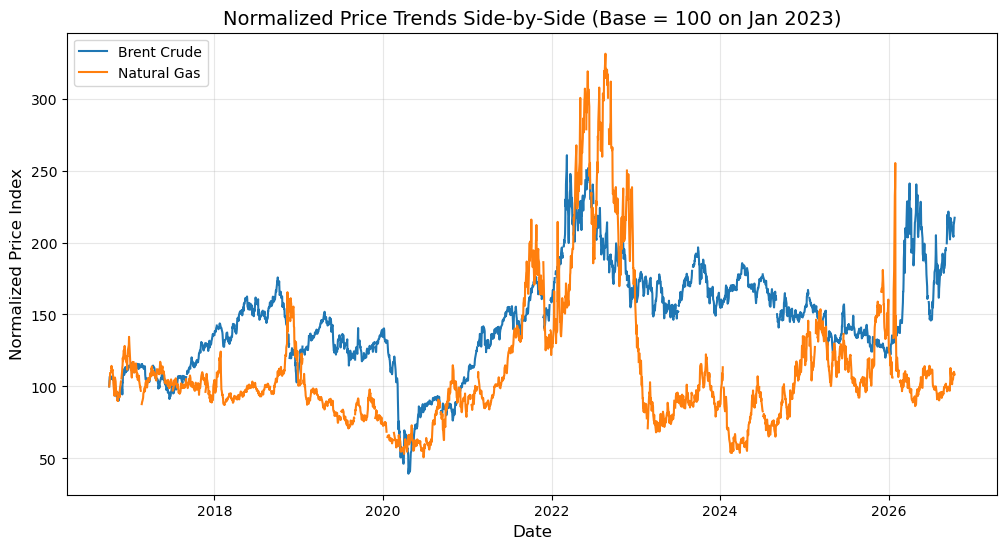

In [5]:
# 2. Normalize prices so they all start at 100 on the first day
normalized_data = (data / data.iloc[0]) * 100

normalized_data_Commodities = normalized_data[["Brent Crude", "Natural Gas"]]
# 3. Plot trends side-by-side
plt.figure(figsize=(12, 6))
for column in normalized_data_Commodities.columns:
  plt.plot(
      normalized_data_Commodities.index, normalized_data_Commodities[column], label=column, linewidth=1.5
  )

plt.title(
    "Normalized Price Trends Side-by-Side (Base = 100 on Jan 2023)", fontsize=14
)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalized Price Index", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

Oil and gas are almost independent of each other, as the correlation is near zero, and they move in a different trend.  

In [6]:
# import statsmodels.api as sm

# # Drop any NaN rows
# clean_returns = log_returns.dropna()

# # Define X (independent variable: Brent Crude) and Y (dependent variable: Natural Gas)
# X = clean_returns["Brent Crude"]
# y = clean_returns["Natural Gas"]

# # Add a constant to X (so the regression calculates an intercept / alpha)
# X_with_const = sm.add_constant(X)

# # Fit the Linear Regression model
# reg_model = sm.OLS(y, X_with_const).fit()

# # Print the regression summary
# print(reg_model.summary())

In [7]:
import sys

!{sys.executable} -m pip install elexonpy


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


## UK wholesale electricity price (Elexon)

Uses Elexon's **Market Index Data (MID)**, the half-hourly wholesale spot price (£/MWh) from the APX/EPEX exchange,
available from 2016. The API only allows **7 days per request**, so the date range is split into weekly chunks,
fetched in parallel and cached to CSV so later runs don't re-download.

In [8]:
import os
import time
from concurrent.futures import ThreadPoolExecutor

import requests

ELEXON_MID_URL = "https://data.elexon.co.uk/bmrs/api/v1/balancing/pricing/market-index"
START, END = "2016-10-01", "2026-10-13"
CACHE_FILE = "uk_power_mid.csv"


def fetch_mid_week(start):
    """Fetch one 7-day chunk of half-hourly MID prices (API limit is 7 days per call)."""
    end = start + pd.Timedelta(days=6, hours=23, minutes=30)
    params = {
        "from": start.strftime("%Y-%m-%dT%H:%MZ"),
        "to": end.strftime("%Y-%m-%dT%H:%MZ"),
        "dataProviders": "APXMIDP",
        "format": "json",
    }
    for attempt in range(3):
        try:
            r = requests.get(ELEXON_MID_URL, params=params, timeout=30)
            r.raise_for_status()
            return pd.DataFrame(r.json()["data"])
        except requests.RequestException:
            time.sleep(2 ** attempt)
    print(f"Failed to fetch week starting {start.date()}")
    return pd.DataFrame()


if os.path.exists(CACHE_FILE):
    mid = pd.read_csv(CACHE_FILE)
else:
    week_starts = pd.date_range(START, END, freq="7D")
    with ThreadPoolExecutor(max_workers=8) as ex:
        mid = pd.concat(ex.map(fetch_mid_week, week_starts), ignore_index=True)
    mid = mid.drop_duplicates(["settlementDate", "settlementPeriod"])
    mid.to_csv(CACHE_FILE, index=False)

# Zero-volume periods carry a placeholder price of 0, so drop them before averaging
mid = mid[mid["volume"] > 0]
mid["date"] = pd.to_datetime(mid["settlementDate"])

# Aggregate the 48 half-hourly prices into a daily average (£/MWh)
uk_power_daily = mid.groupby("date")["price"].mean().rename("UK Power")

print(f"{len(mid):,} half-hourly rows -> {len(uk_power_daily):,} days")
print(uk_power_daily.resample("YE").mean().round(1))

173,026 half-hourly rows -> 3,630 days
date
2016-12-31     50.2
2017-12-31     44.7
2018-12-31     56.9
2019-12-31     41.8
2020-12-31     33.5
2021-12-31    114.7
2022-12-31    198.2
2023-12-31     93.6
2024-12-31     71.4
2025-12-31     79.9
2026-12-31    104.4
Freq: YE-DEC, Name: UK Power, dtype: float64


## Merge with oil and gas

UK power prices are set mostly by **European gas**, so add Dutch TTF gas (`TTF=F`, €/MWh, history starts in late 2017)
alongside Brent and US Henry Hub gas (`NG=F`).

Power trades every day but futures only trade on weekdays, so an inner join keeps trading days only.
That's why the earlier single-day attempt (2026-10-10, a Saturday) returned 0 rows.

Aligned trading days: 2232 (2017-10-23 to 2026-10-12)


/var/folders/m5/pl7f3qbs4wz97g9ld9_84ysw0000gn/T/ipykernel_66438/1483115706.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  energy_px = yf.download(list(energy_tickers.values()), start=START, end=END, progress=False)["Close"]
/opt/anaconda3/lib/python3.12/site-packages/yfinance/scrapers/history.py:204: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  dt_now = pd.Timestamp.utcnow()


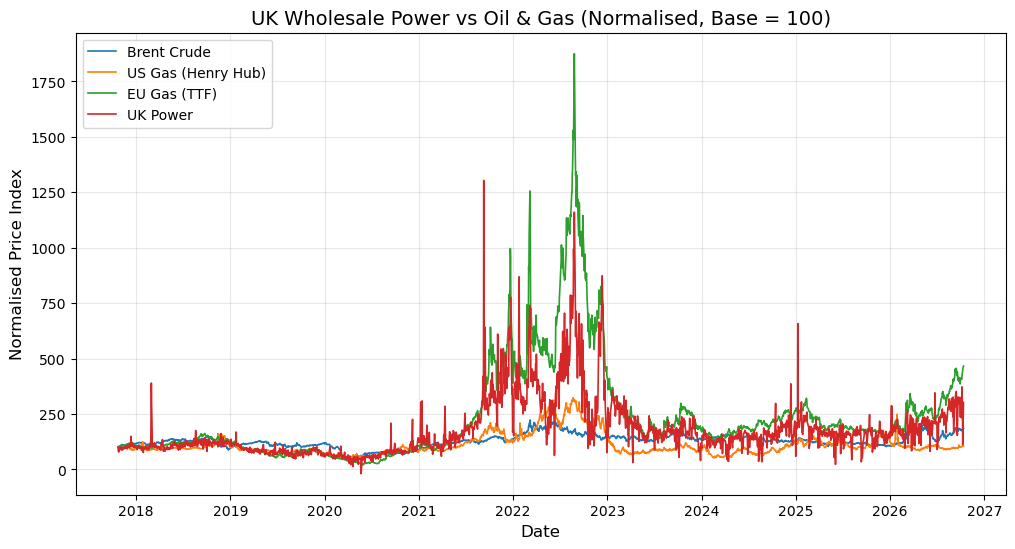

In [9]:
energy_tickers = {"Brent Crude": "BZ=F", "US Gas (Henry Hub)": "NG=F", "EU Gas (TTF)": "TTF=F"}

energy_px = yf.download(list(energy_tickers.values()), start=START, end=END, progress=False)["Close"]
energy_px = energy_px.rename(columns={v: k for k, v in energy_tickers.items()})

master = energy_px.join(uk_power_daily, how="inner").dropna()
print(f"Aligned trading days: {len(master)} ({master.index[0].date()} to {master.index[-1].date()})")

# Normalised trends (base = 100 on first common day)
normalized_master = master / master.iloc[0] * 100

plt.figure(figsize=(12, 6))
for column in normalized_master.columns:
    plt.plot(normalized_master.index, normalized_master[column], label=column, linewidth=1.2)
plt.title("UK Wholesale Power vs Oil & Gas (Normalised, Base = 100)", fontsize=14)
plt.xlabel("Date", fontsize=12)
plt.ylabel("Normalised Price Index", fontsize=12)
plt.legend(loc="upper left")
plt.grid(True, alpha=0.3)
plt.show()

## Past year: UK power vs EU & US gas (normalised)

The three series are in different units (£/MWh, €/MWh, $/MMBtu), so they are normalised to compare shape:
- **Rebased to 100** shows the percentage move since the start of the window.
- **Z-score** puts each series in its own standard deviations, so a volatile series doesn't dominate the chart.

A 5-day rolling mean removes the daily wind/weekend noise in UK power.

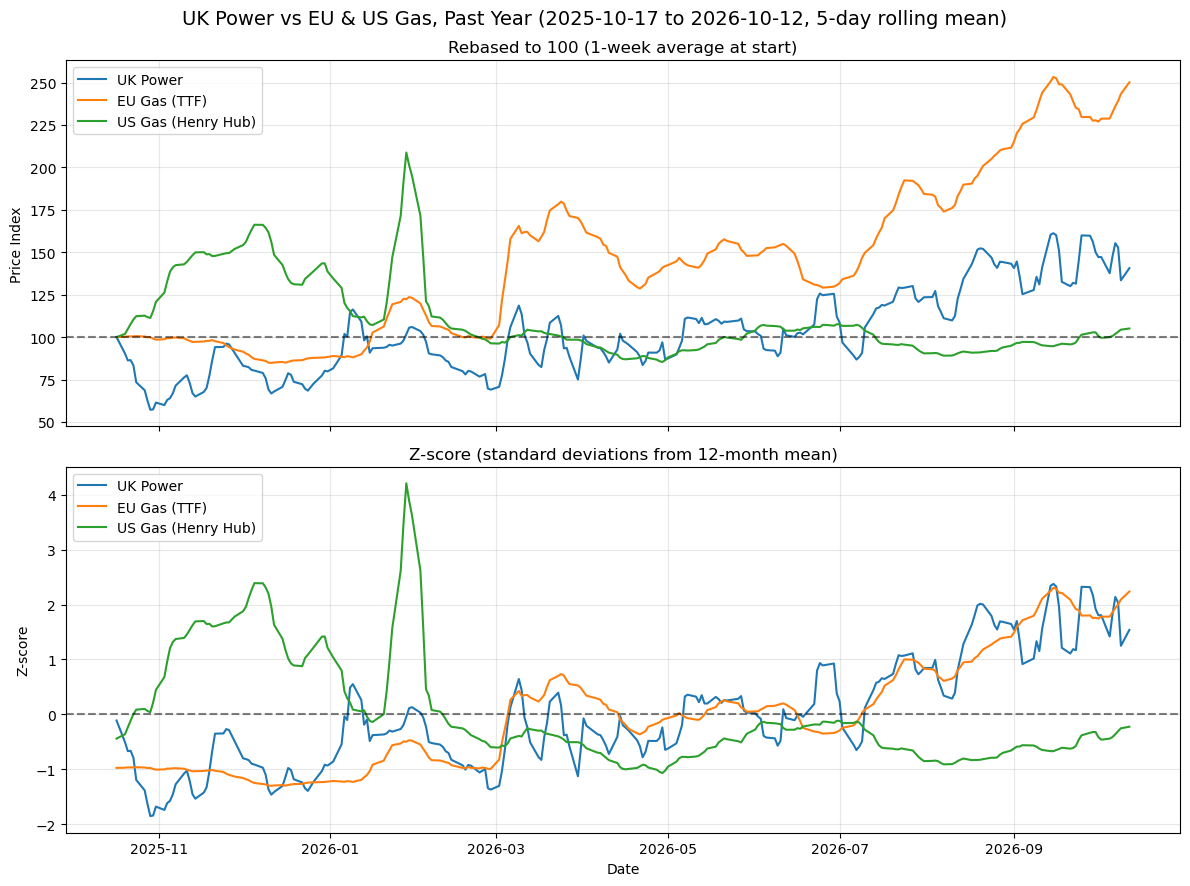

In [10]:
# Last 12 months of UK power, EU gas and US gas
last_year = master.loc[master.index[-1] - pd.DateOffset(years=1):, ["UK Power", "EU Gas (TTF)", "US Gas (Henry Hub)"]]

# Daily UK power is noisy (wind, weekends), so smooth all three with a 5-trading-day (1-week) rolling mean
smoothed = last_year.rolling(5).mean().dropna()

# Rebase to 100 on the first week (shows % moves) and z-score (shows shape, ignores volatility differences)
rebased = smoothed / smoothed.iloc[0] * 100
zscored = (smoothed - smoothed.mean()) / smoothed.std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
for col in rebased.columns:
    ax1.plot(rebased.index, rebased[col], label=col, linewidth=1.5)
    ax2.plot(zscored.index, zscored[col], label=col, linewidth=1.5)

ax1.axhline(100, color="black", linestyle="--", alpha=0.5)
ax1.set_title("Rebased to 100 (1-week average at start)", fontsize=12)
ax1.set_ylabel("Price Index")
ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
ax2.set_title("Z-score (standard deviations from 12-month mean)", fontsize=12)
ax2.set_ylabel("Z-score")
ax2.set_xlabel("Date")
for ax in (ax1, ax2):
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)
fig.suptitle(
    f"UK Power vs EU & US Gas, Past Year ({smoothed.index[0].date()} to {smoothed.index[-1].date()}, 5-day rolling mean)",
    fontsize=14,
)
plt.tight_layout()
plt.show()

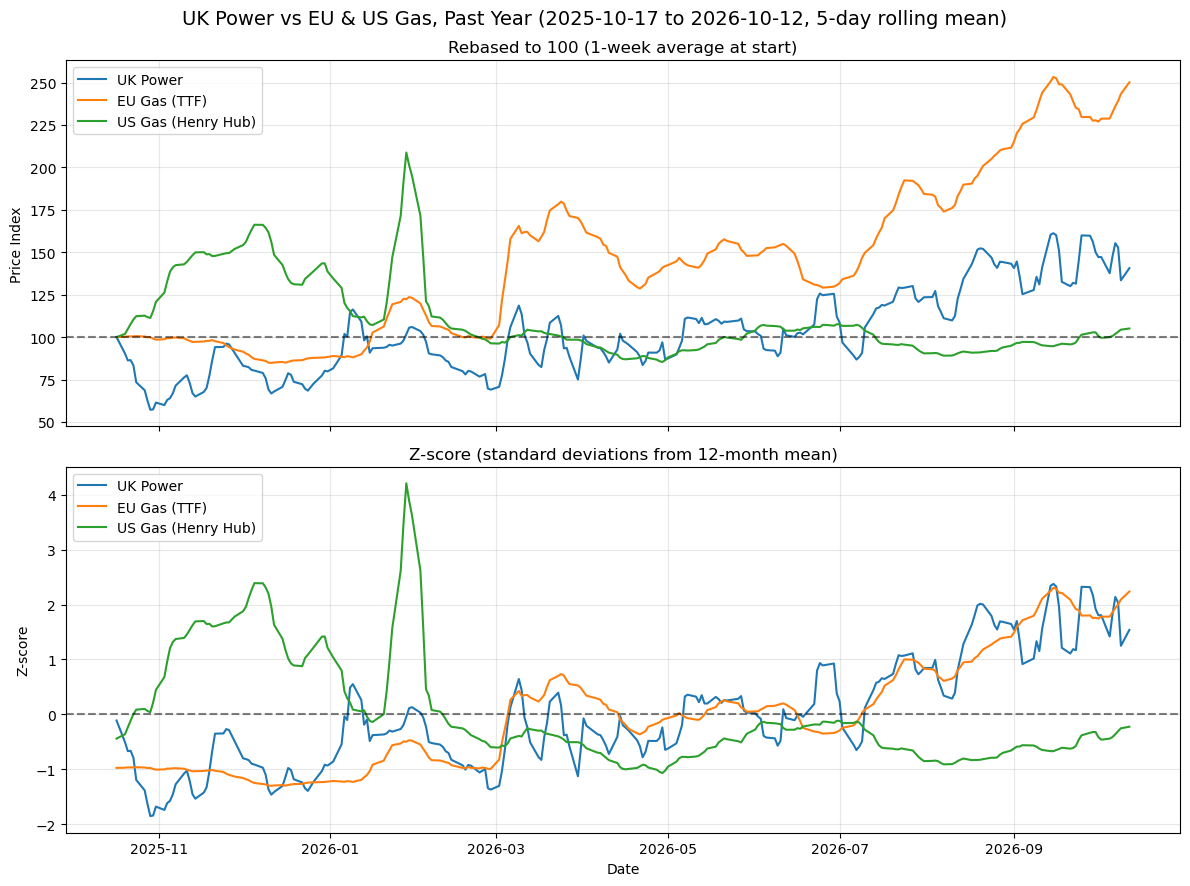

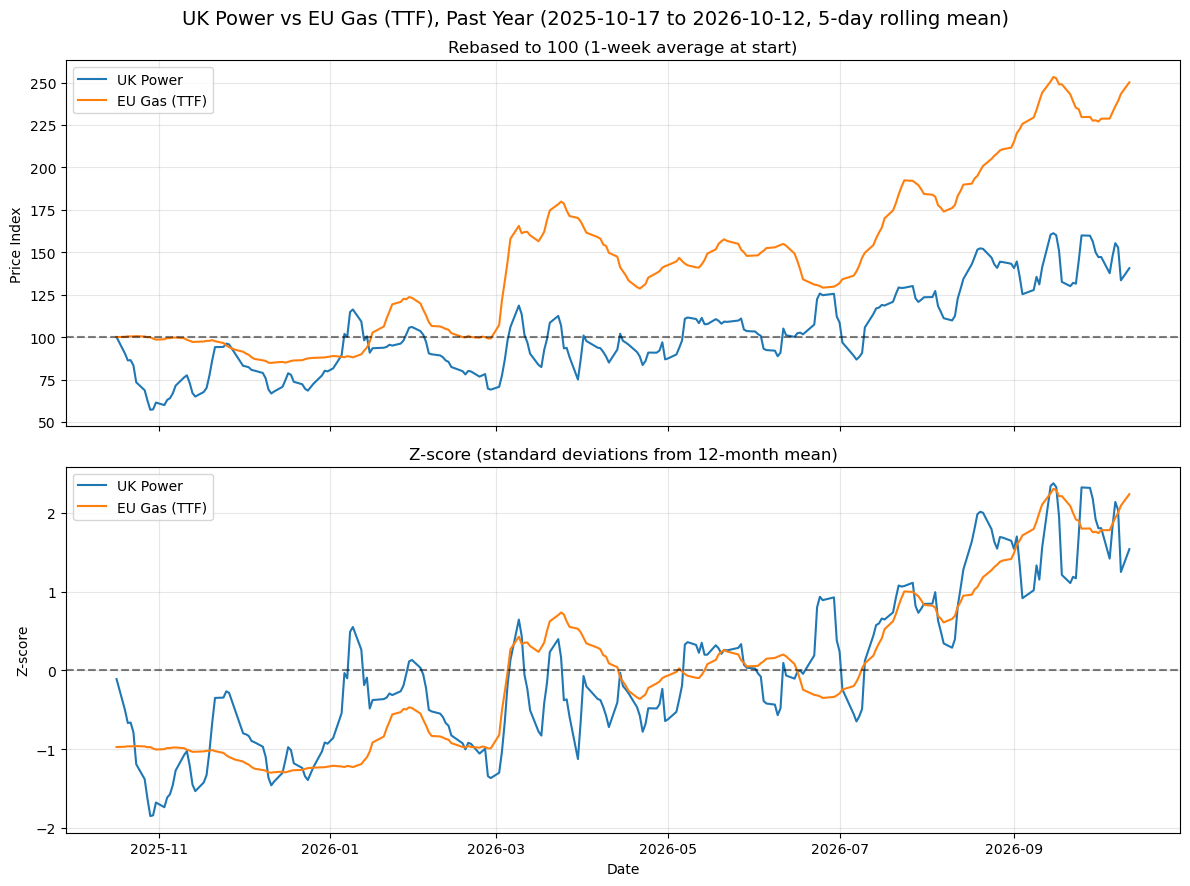

In [12]:
import matplotlib.pyplot as plt


# 1. Define a reusable plotting function
def plot_energy_comparison(df, columns_to_plot, title_suffix):
  # Filter data for the last year and specific columns
  last_year = df.loc[
      df.index[-1] - pd.DateOffset(years=1) :, columns_to_plot
  ]

  # Smooth with a 5-trading-day rolling mean to remove noise
  smoothed = last_year.rolling(5).mean().dropna()

  # Transform data: Rebase to 100 and calculate Z-scores
  rebased = smoothed / smoothed.iloc[0] * 100
  zscored = (smoothed - smoothed.mean()) / smoothed.std()

  # Setup the 2-panel figure layout
  fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharex=True)

  for col in columns_to_plot:
    ax1.plot(rebased.index, rebased[col], label=col, linewidth=1.5)
    ax2.plot(zscored.index, zscored[col], label=col, linewidth=1.5)

  # Formatting Panel 1 (Rebased)
  ax1.axhline(100, color="black", linestyle="--", alpha=0.5)
  ax1.set_title("Rebased to 100 (1-week average at start)", fontsize=12)
  ax1.set_ylabel("Price Index")

  # Formatting Panel 2 (Z-score)
  ax2.axhline(0, color="black", linestyle="--", alpha=0.5)
  ax2.set_title(
      "Z-score (standard deviations from 12-month mean)", fontsize=12
  )
  ax2.set_ylabel("Z-score")
  ax2.set_xlabel("Date")

  for ax in (ax1, ax2):
    ax.legend(loc="upper left")
    ax.grid(True, alpha=0.3)

  fig.suptitle(
      f"{title_suffix} ({smoothed.index[0].date()} to"
      f" {smoothed.index[-1].date()}, 5-day rolling mean)",
      fontsize=14,
  )
  plt.tight_layout()
  plt.show()


# ==========================================
# 2. Plot all three (Your original plot)
# ==========================================
plot_energy_comparison(
    master,
    ["UK Power", "EU Gas (TTF)", "US Gas (Henry Hub)"],
    "UK Power vs EU & US Gas, Past Year",
)

# ==========================================
# 3. Plot ONLY EU Gas and UK Power (Super clean!)
# ==========================================
plot_energy_comparison(
    master, ["UK Power", "EU Gas (TTF)"], "UK Power vs EU Gas (TTF), Past Year"
)

--- Correlation of UK Power with oil & gas ---
                    Price levels  Daily returns  Weekly returns  \
Brent Crude                0.550          0.014           0.068   
US Gas (Henry Hub)         0.697         -0.032           0.058   
EU Gas (TTF)               0.870          0.065           0.339   

                    Monthly returns  
Brent Crude                   0.048  
US Gas (Henry Hub)            0.259  
EU Gas (TTF)                  0.679  


/opt/anaconda3/lib/python3.12/site-packages/pandas/core/internals/blocks.py:347: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)


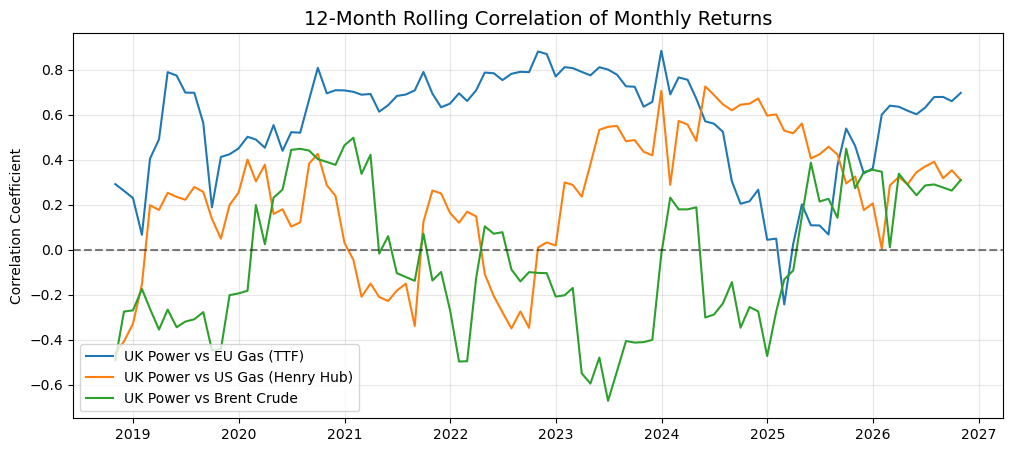

In [11]:
corr_table = pd.DataFrame({
    "Price levels": master.corr()["UK Power"],
    "Daily returns": np.log(master).diff().corr()["UK Power"],
    "Weekly returns": np.log(master.resample("W-FRI").mean()).diff().corr()["UK Power"],
    "Monthly returns": np.log(master.resample("ME").mean()).diff().corr()["UK Power"],
}).drop("UK Power")

print("--- Correlation of UK Power with oil & gas ---")
print(corr_table.round(3))

# Rolling 12-month correlation of monthly returns
monthly_ret = np.log(master.resample("ME").mean()).diff().dropna()
plt.figure(figsize=(12, 5))
for col in ["EU Gas (TTF)", "US Gas (Henry Hub)", "Brent Crude"]:
    plt.plot(monthly_ret["UK Power"].rolling(12).corr(monthly_ret[col]), label=f"UK Power vs {col}")
plt.axhline(0, color="black", linestyle="--", alpha=0.5)
plt.title("12-Month Rolling Correlation of Monthly Returns", fontsize=14)
plt.ylabel("Correlation Coefficient")
plt.legend(loc="lower left")
plt.grid(True, alpha=0.3)
plt.show()

correlation of EU Gas and Energy price. 